# 02c · Robustness of the community step

Do the communities, and the RQ1 result built on them, depend on how notebook 02 found them? Each variant
changes **one** setting of the main run (D19). Backbones are in notebook 02b.

| Variant | What changes | Question |
|---|---|---|
| seeds 1–10 | random seed | Is the partition stable, or one lucky draw? |
| γ = 0.5 / 2.0 | resolution (coarser / finer) | Does RQ1 depend on how fine the communities are? |
| unweighted | every edge counts 1 | Do a few heavy edges drive the communities? |
| undirected Leiden | direction ignored (w_ij + w_ji) | Does direction matter? |
| Louvain (undirected) | other algorithm (D19) | Is it specific to Leiden? |
| English-only graph | only English–English edges | Do non-English channels shape the English communities? |

RQ1 is recomputed for every variant exactly as in notebook 03 (channel-level topics, English text
forwards, B = 1,000, seed 42). Partitions are cached in `tgdata/derived/robustness/`.

In [1]:
import json, sys, time
from pathlib import Path

import igraph as ig
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("src").resolve()))
from tgperm import config as cfg, data, graph, plots, crossing
from tgperm.describe import mix, composition, impurity_summary, blocks, purity, crossing_mask

plots.use_style()
OUT = cfg.RESULTS / "02c"   # this notebook's tables and figures
OUT.mkdir(parents=True, exist_ok=True)
CACHE = cfg.DERIVED / "robustness"
CACHE.mkdir(exist_ok=True)

con = data.connect()
channels = data.channel_table(con)
ch_all = channels.set_index("channel_id")
cons_of = ch_all.conspiracy
edges = pd.read_parquet(cfg.DERIVED / "edges_full.parquet")
edges_en = pd.read_parquet(cfg.DERIVED / "edges_en.parquet")
fw = pd.read_parquet(data.build_en_text_windows(con))
main = pd.read_parquet(cfg.DERIVED / "communities.parquet").set_index("channel_id").community

g = graph.to_igraph(edges)
ids = np.asarray(g.vs["channel_id"], dtype="int64")
g_unw = g.copy(); g_unw.es["weight"] = 1.0
g_und = g.as_undirected(mode="collapse", combine_edges={"weight": "sum"})

## 1 · The variants

In [2]:
variants = {f"seed {s}": dict(graph=g, kind="leiden", resolution=1.0, seed=s) for s in range(1, 11)}
variants.update({"γ = 0.5": dict(graph=g, kind="leiden", resolution=0.5, seed=42),
                 "γ = 2.0": dict(graph=g, kind="leiden", resolution=2.0, seed=42),
                 "unweighted": dict(graph=g_unw, kind="leiden", resolution=1.0, seed=42),
                 "undirected Leiden": dict(graph=g_und, kind="leiden", resolution=1.0, seed=42),
                 "Louvain (undirected)": dict(graph=g_und, kind="louvain", resolution=1.0, seed=42)})
parts = {"main": main}
for name, v in variants.items():
    tag = name.replace(" ", "_").replace("=", "").replace("γ", "res").replace("(", "").replace(")", "").replace(".", "p")
    f, fm = CACHE / f"communities_{tag}.parquet", CACHE / f"communities_{tag}_meta.json"
    if not f.exists():
        mem, meta = (graph.leiden(v["graph"], resolution=v["resolution"], seed=v["seed"]) if v["kind"] == "leiden"
                     else graph.louvain(v["graph"], seed=v["seed"]))
        pd.DataFrame({"channel_id": ids, "community": mem.astype("int32")}).to_parquet(f, index=False)
        fm.write_text(json.dumps(meta | {"variant": name}, indent=2))
    parts[name] = pd.read_parquet(f).set_index("channel_id").community
print({n: p.nunique() for n, p in parts.items()})

{'main': 289, 'seed 1': 305, 'seed 2': 300, 'seed 3': 298, 'seed 4': 299, 'seed 5': 301, 'seed 6': 281, 'seed 7': 298, 'seed 8': 304, 'seed 9': 303, 'seed 10': 312, 'γ = 0.5': 220, 'γ = 2.0': 399, 'unweighted': 44, 'undirected Leiden': 296, 'Louvain (undirected)': 222}


## 2 · How different are the partitions?

Modularity is evaluated for every partition on the same directed weighted graph, so values are
comparable. NMI and ARI measure agreement with the main partition (1 = identical).

In [3]:
sab = set(channels.channel_id[channels.sabmyk])
en_ch = channels[channels.language == "en"].set_index("channel_id")
topics = sorted(en_ch.ch_topic.unique())

def structure(part):
    a, b = main.reindex(part.index).to_numpy(), part.to_numpy()
    t = edges_en.n_text.to_numpy()
    x, cov = crossing_mask(edges_en, part)
    chp = ch_all.loc[part.index].reset_index().assign(community=b)
    en_in = part[part.index.isin(en_ch.index)]
    tc = pd.Categorical(en_ch.ch_topic.reindex(en_in.index), categories=topics).codes.astype(np.int64)
    bl = blocks(edges_en, "n_text", part, cons_of).loc["across communities"]
    return {"communities": part.nunique(), "communities ≥ 100 channels": int((part.value_counts() >= 100).sum()),
            "directed modularity": g.modularity(pd.factorize(part.reindex(ids))[0].tolist(), weights="weight", directed=True),
            "NMI with main": ig.compare_communities(pd.factorize(a)[0].tolist(), pd.factorize(b)[0].tolist(), method="nmi"),
            "ARI with main": ig.compare_communities(pd.factorize(a)[0].tolist(), pd.factorize(b)[0].tolist(), method="adjusted_rand"),
            "Sabmyk in one community (of 236)": int(part[part.index.isin(sab)].value_counts().iloc[0]),
            "English text forwards crossing": t[x].sum() / t[cov].sum(),
            "crossings involving a conspiracy channel": 1 - bl["N→N"] / bl.sum(),
            "conspiracy impurity reduction": impurity_summary(chp, composition(chp))["impurity_reduction"],
            "channel-topic purity (English)": purity(pd.factorize(en_in.to_numpy())[0], tc)[0]}

struct = pd.DataFrame({name: structure(p) for name, p in parts.items()}).T
struct.to_csv(OUT / "02c_structure.csv")
def fmt(col):
    if col.name.startswith(("NMI", "ARI", "directed")): return col.map(lambda v: f"{v:.3f}")
    if col.name.startswith(("English", "crossings", "conspiracy", "channel-topic")): return col.map("{:.1%}".format)
    return col.map("{:,.0f}".format)
struct.apply(fmt)

,communities,communities ≥ 100 channels,directed modularity,NMI with main,ARI with main,Sabmyk in one community (of 236),English text forwards crossing,crossings involving a conspiracy channel,conspiracy impurity reduction,channel-topic purity (English)
main,289,34,0.862,1.000,1.000,234,5.0%,93.8%,34.7%,49.9%
seed 1,305,32,0.859,0.955,0.935,234,5.0%,94.1%,34.6%,50.1%
seed 2,300,33,0.862,0.963,0.957,234,5.0%,93.8%,34.6%,50.4%
seed 3,298,33,0.860,0.966,0.956,234,5.0%,94.2%,34.6%,50.4%
seed 4,299,32,0.859,0.943,0.894,234,5.0%,94.1%,34.5%,50.1%
seed 5,301,31,0.862,0.970,0.973,234,5.0%,93.9%,34.5%,50.3%
seed 6,281,36,0.862,0.962,0.950,234,5.0%,94.1%,34.3%,50.3%
seed 7,298,35,0.862,0.961,0.950,234,5.0%,93.8%,34.7%,50.1%
seed 8,304,34,0.862,0.965,0.964,234,5.0%,94.2%,34.4%,50.3%
seed 9,303,35,0.860,0.933,0.880,234,5.0%,93.6%,34.2%,51.9%


In [4]:
seed_names = ["main"] + [f"seed {s}" for s in range(1, 11)]
codes = {n: pd.factorize(parts[n].reindex(ids))[0].tolist() for n in seed_names}
pair = [ig.compare_communities(codes[a], codes[b], method="nmi") for i, a in enumerate(seed_names) for b in seed_names[i + 1:]]
seeds = struct.loc[seed_names]
print(f"11 seeds: pairwise NMI mean {np.mean(pair):.3f} (min {np.min(pair):.3f}); communities "
      f"{seeds.communities.min():.0f}–{seeds.communities.max():.0f}; main has the highest modularity: "
      f"{seeds['directed modularity'].astype(float).idxmax() == 'main'}")

11 seeds: pairwise NMI mean 0.951 (min 0.907); communities 281–312; main has the highest modularity: True


**The one variant that changes the picture, γ = 0.5, merges C6 and C7**, the two English conspiracy-heavy
communities (far-right & conspiracy; right-wing news & Covid). Every other variant keeps them apart:

In [5]:
c6, c7 = main.index[main == 6], main.index[main == 7]
sep = pd.DataFrame([{"variant": n, "C6 → its main community": f"{p.reindex(c6).value_counts(normalize=True).iloc[0]:.0%}",
                     "C7 → its main community": f"{p.reindex(c7).value_counts(normalize=True).iloc[0]:.0%}",
                     "C6 and C7 separate": p.reindex(c6).value_counts().index[0] != p.reindex(c7).value_counts().index[0]}
                    for n, p in parts.items() if n != "main"])
r05 = parts["γ = 0.5"].reindex(main.index)
into = {}
for c in range(15):
    into.setdefault(int(r05[main == c].value_counts().index[0]), []).append(f"C{c}")
print("among the 15 largest, main communities merged at γ = 0.5:", [v for v in into.values() if len(v) > 1])
sep.style.hide(axis="index")

among the 15 largest, main communities merged at γ = 0.5: [['C1', 'C10'], ['C6', 'C7']]


variant,C6 → its main community,C7 → its main community,C6 and C7 separate
seed 1,99%,98%,True
seed 2,98%,98%,True
seed 3,99%,98%,True
seed 4,100%,98%,True
seed 5,100%,98%,True
seed 6,99%,97%,True
seed 7,99%,98%,True
seed 8,99%,98%,True
seed 9,98%,98%,True
seed 10,99%,98%,True


## 3 · Does the RQ1 result change?

*Verdicts kept* = topics with the same verdict (more / less / not distinguishable than that variant's
overall rate) as the main run; *Spearman* = rank correlation of the 13 topic rates with the main run.

In [6]:
topic_of = ch_all.ch_topic
fw = fw.assign(topic=fw.src_id.map(topic_of).map({t: i for i, t in enumerate(topics)}))

def rq1(part):
    x, cov = crossing_mask(fw, part)
    d = fw[cov]
    rows = pd.DataFrame({"topic": d.topic.to_numpy(), "source": d.src_id.to_numpy(), "n": d.n_text.to_numpy(), "x": d.n_text.to_numpy() * x[cov]})
    return crossing.topic_table(rows, topics, B=1000, seed=cfg.SEED).set_index("topic")

rq = {name: rq1(p) for name, p in parts.items()}
base = rq["main"]
summ = pd.DataFrame({name: {"overall crossing rate": t.attrs["overall_rate"],
                            "Spearman with main": t.rate.rank().corr(base.rate.rank()),
                            "verdicts kept (of 13)": int((t.verdict == base.verdict).sum()),
                            "changed": ", ".join(f"{k}: {base.verdict[k]} → {t.verdict[k]}" for k in t.index[t.verdict != base.verdict]) or "—"}
                     for name, t in rq.items()}).T
summ.to_csv(OUT / "02c_rq1_summary.csv")
summ.style.format({"overall crossing rate": "{:.1%}", "Spearman with main": "{:.2f}"})

,overall crossing rate,Spearman with main,verdicts kept (of 13),changed
main,5.0%,1.00,13,—
seed 1,5.0%,1.00,13,—
seed 2,5.0%,0.99,12,Extremists and radicals: less → not distinguishable
seed 3,5.0%,0.99,13,—
seed 4,5.0%,1.00,13,—
seed 5,5.0%,0.99,13,—
seed 6,5.0%,1.00,13,—
seed 7,5.0%,1.00,12,Extremists and radicals: less → not distinguishable
seed 8,5.0%,1.00,13,—
seed 9,5.0%,1.00,12,Extremists and radicals: less → not distinguishable


**Figure 1.** RQ1 crossing rate by source-channel topic under each variant; the legend gives each
variant's agreement with the main run (partition NMI · RQ1 verdicts kept). English text forwards; edges
`src -> dest`.

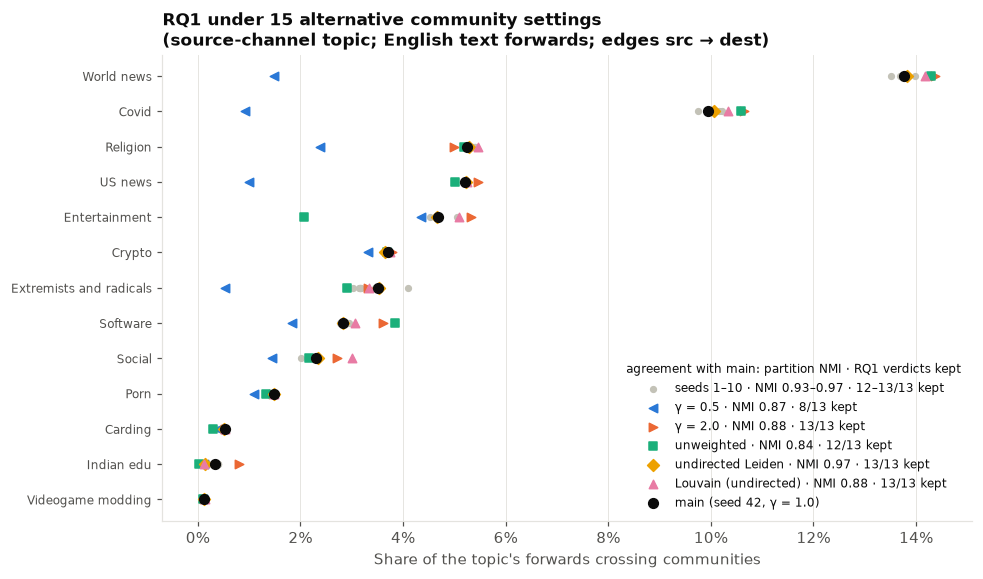

In [7]:
order = base.sort_values("rate").index.tolist()
y = np.arange(len(order))
others, markers = ["γ = 0.5", "γ = 2.0", "unweighted", "undirected Leiden", "Louvain (undirected)"], ["<", ">", "s", "D", "^"]
nmi_s = struct.loc[seed_names[1:], "NMI with main"].astype(float)
kept_s = summ.loc[seed_names[1:], "verdicts kept (of 13)"].astype(int)
fig, ax = plt.subplots(figsize=(9.5, 5.5))
for s in range(1, 11):
    ax.scatter(rq[f"seed {s}"].rate.reindex(order), y, color="#c3c2b7", s=14, zorder=2,
               label=f"seeds 1–10 · NMI {nmi_s.min():.2f}–{nmi_s.max():.2f} · {kept_s.min()}–{kept_s.max()}/13 kept" if s == 1 else None)
for k, (name, mk) in enumerate(zip(others, markers)):
    ax.scatter(rq[name].rate.reindex(order), y, color=plots.SERIES[k], marker=mk, s=30, zorder=3,
               label=f"{name} · NMI {float(struct.loc[name, 'NMI with main']):.2f} · {int(summ.loc[name, 'verdicts kept (of 13)'])}/13 kept")
ax.scatter(base.rate.reindex(order), y, color=plots.INK, s=40, zorder=4, label="main (seed 42, γ = 1.0)")
ax.set_yticks(y, order, fontsize=8); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(lambda v, _: f"{100 * v:g}%")
ax.set_xlabel("Share of the topic's forwards crossing communities")
ax.set_title("RQ1 under 15 alternative community settings\n(source-channel topic; English text forwards; edges src → dest)", loc="left")
ax.legend(loc="lower right", fontsize=8, title="agreement with main: partition NMI · RQ1 verdicts kept", title_fontsize=8)
plots.savefig(fig, "02c_fig1_rq1_variants", OUT)
plt.show()

## 4 · Communities from the English–English graph only (D9)

Leiden with the main settings on the English graph, compared with the main partition restricted to the
same channels. The full graph stays the main border: it sees paths through non-English channels.

In [8]:
g_en = graph.to_igraph(edges_en)
mem_en, meta_en = graph.leiden(g_en)
en_ids = np.asarray(g_en.vs["channel_id"], dtype="int64")
c_en = pd.Series(mem_en, index=en_ids)
full_on_en = pd.factorize(main.reindex(en_ids).to_numpy())[0]
ch_en = ch_all.loc[en_ids].reset_index()
t_en = pd.Categorical(ch_en.ch_topic, categories=topics).codes.astype(np.int64)

def rate(part):
    c = edges_en.src_id.map(part).to_numpy() != edges_en.dest_id.map(part).to_numpy()
    return edges_en.n_text.to_numpy()[c].sum() / edges_en.n_text.sum()

def desc(codes):
    chp = ch_en.assign(community=codes)
    return {"communities with English channels": len(np.unique(codes)),
            "… with ≥ 100 English channels": int((pd.Series(codes).value_counts() >= 100).sum()),
            "directed modularity on the English graph": g_en.modularity(pd.factorize(codes)[0].tolist(), weights="weight", directed=True),
            "conspiracy impurity reduction": impurity_summary(chp, composition(chp))["impurity_reduction"],
            "channel-topic purity": purity(pd.factorize(codes)[0], t_en)[0]}

cmp = pd.DataFrame({"main (full graph), on English channels": {**desc(full_on_en), "crossing share, English text forwards": rate(main)},
                    "English-only partition": {**desc(mem_en), "crossing share, English text forwards": rate(c_en)}})
print(f"agreement on {len(en_ids):,} English channels: NMI {ig.compare_communities(full_on_en.tolist(), mem_en.tolist(), method='nmi'):.3f}, "
      f"ARI {ig.compare_communities(full_on_en.tolist(), mem_en.tolist(), method='adjusted_rand'):.3f}")
cmp.style.format(lambda v: f"{v:,.0f}" if abs(v) >= 2 else f"{v:.3f}")

agreement on 18,216 English channels: NMI 0.800, ARI 0.762


,"main (full graph), on English channels",English-only partition
communities with English channels,74,141
… with ≥ 100 English channels,16,17
directed modularity on the English graph,0.723,0.737
conspiracy impurity reduction,0.385,0.382
channel-topic purity,0.515,0.576
"crossing share, English text forwards",0.050,0.102


In [9]:
# The largest English-only communities and where they sit in the main partition
rows = []
for c in range(10):
    m = ch_en[mem_en == c]
    fc = main.reindex(m.channel_id).value_counts()
    rows.append({"English-only community": c, "channels": len(m), "conspiracy share": m.conspiracy.mean(),
                 "main community": f"C{fc.index[0]}", "overlap": fc.iloc[0] / len(m),
                 "second": f"C{fc.index[1]} ({fc.iloc[1] / len(m):.0%})" if len(fc) > 1 else ""})
pd.DataFrame(rows).style.format({"channels": "{:,}", "conspiracy share": "{:.0%}", "overlap": "{:.0%}"}).hide(axis="index")

English-only community,channels,conspiracy share,main community,overlap,second
0,"3,896",40%,C6,93%,C4 (2%)
1,"2,960",1%,C8,100%,C32 (0%)
2,"2,294",66%,C7,97%,C5 (2%)
3,"1,990",8%,C4,87%,C1 (9%)
4,"1,575",1%,C11,75%,C9 (10%)
5,"1,361",71%,C7,93%,C6 (3%)
6,791,3%,C14,98%,C11 (1%)
7,659,4%,C15,73%,C1 (14%)
8,325,59%,C6,70%,C7 (25%)
9,317,21%,C19,97%,C2 (1%)
